## Import libraries

In [48]:
import numpy as np
import pandas as pd
from utils_cp import *
from collections import defaultdict
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import json
from tqdm import tqdm

## Read data

In [49]:
mIRageLibraySpectra_Removed = pd.read_csv('mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'

In [50]:
with open('pilot_phase_data_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

#with open('pilot_phase_data_raman_saturation_trunc.json', 'r') as f:
#    saturated_wn_dict_trunc = json.load(f)
    
ids_sat = list(saturated_wn_dict.keys())

#ids_sat_trunc = list(saturated_wn_dict_trunc.keys())
#ids_sat_diff = np.array(ids_sat)[[x not in ids_sat_trunc for x in ids_sat]]

slopp_df = pd.read_csv('slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])
slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)

rebecca_df = pd.read_csv('rebecca_data_raman_final_specy.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_df = rebecca_df.query('polymer == "PE"').reset_index(drop=True)

#label_table_rb = pd.DataFrame({'label':np.arange(3),
#    'polymer':np.unique(rebecca_df['polymer'])})
#label_table_rb
#rebecca_df = rebecca_df.merge(label_table_rb)

stearates_df = pd.read_csv('stearates_data_raman_final_specy.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])
#stearates_df['polymer'] = "Stearate"

stearates_df_not_lib = pd.read_csv('stearates_data_not_lib_raman_final_specy.csv')
del stearates_df_not_lib['Unnamed: 0']
stearates_df_not_lib.columns = list(np.float64(stearates_df_not_lib.columns[:-4])) + list(stearates_df_not_lib.columns[-4:])

rm_nan = np.unique(np.where(np.isnan(stearates_df_not_lib.iloc[:,:-4]))[0])[0]
stearates_df_not_lib = stearates_df_not_lib.drop(rm_nan, axis=0).reset_index(drop=True)

#label_table_st = pd.DataFrame({'label':np.arange(4),
#    'polymer':np.unique(stearates_df['polymer'])})
#label_table_st
#stearates_df = stearates_df.merge(label_table_st)

pilot_phase_data_raman = pd.read_csv('pilot_phase_data_raman_final_specy.csv')
del pilot_phase_data_raman['Unnamed: 0']
pilot_phase_data_raman.columns = list(np.float64(pilot_phase_data_raman.columns[:-4])) + list(pilot_phase_data_raman.columns[-4:])
pilot_phase_data_raman = pilot_phase_data_raman.query('id not in @ids_sat').reset_index(drop=True)
pilot_phase_data_raman['polymer'] = ''
pilot_phase_data_raman['label'] = ''
del pilot_phase_data_raman['school']

matches_all_raman = pd.read_csv('pilot_phase_data_raman_res.csv')
idx_str_matches_raman = matches_all_raman.query('hqi_rebecca >= .7').loc[:,['id']]

pilot_phase_data_raman = pilot_phase_data_raman.merge(idx_str_matches_raman, on='id').reset_index(drop=True)
pilot_phase_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,id,polymer,label
0,-0.340492,-0.352334,-0.306848,-0.255907,-0.289309,-0.323057,-0.357466,-0.354209,-0.326792,-0.331842,...,-0.513759,-0.513759,-0.513759,-0.513759,-0.513759,862.299988,1482.300049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_9,,
1,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,...,-0.531420,-0.531420,-0.531420,-0.474118,-0.385328,814.099976,1492.050049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_12,,
2,-0.277306,-0.336811,-0.348638,-0.348592,-0.335259,-0.333589,-0.354056,-0.365401,-0.370895,-0.383777,...,-0.725174,-0.725174,-0.725174,-0.725174,-0.725174,817.000000,1492.500000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_13,,
3,-0.556417,-0.673642,-0.606882,-0.516284,-0.624353,-0.695136,-0.695136,-0.695136,-0.695136,-0.695136,...,-0.695136,-0.695136,-0.695136,-0.695136,-0.695136,811.500000,1497.650024,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_14,,
4,-0.516533,-0.434363,-0.338199,-0.258553,-0.402470,-0.558385,-0.737076,-0.665179,-0.432544,-0.408454,...,-0.806905,-0.806905,-0.806905,-0.806905,-0.806905,779.000000,1499.000000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_16,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,-0.699487,-0.699487,-0.699487,-0.687681,-0.541639,-0.496373,-0.642416,-0.699487,-0.699487,-0.699487,...,-0.699487,-0.699487,-0.699487,-0.699487,-0.699487,-180.550003,-642.000000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_115,,
91,-0.278008,-0.372375,-0.497052,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,...,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,-195.050003,-641.500000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_116,,
92,-0.220512,-0.238062,-0.308327,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,...,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,-172.350006,-638.400024,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_117,,
93,-0.756751,-0.756751,-0.554271,-0.325309,-0.312150,-0.393617,-0.654717,-0.579799,-0.289343,-0.354823,...,-0.756751,-0.674039,-0.457049,-0.520136,-0.737126,-163.500000,-631.200012,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_118,,


In [51]:
np.unique(rebecca_df['polymer'])

array(['PE'], dtype=object)

In [52]:

def gen_data_sets(data_1, data_2, data_3, data_test, seed):
    
    np.random.seed(seed)
    #idx_ref = np.random.rand(data_2.shape[0]) > .80
    
    poly_list_data_2 = np.unique(data_2['polymer'])
    idx_strat = [np.where(data_2['polymer'] == p)[0] for p in poly_list_data_2]
    ids_ref = np.concatenate([np.random.choice(x, size=int(x.shape[0]/2), replace=False) for x in idx_strat])
    idx_ref = np.array([i in ids_ref for i in range(data_2.shape[0])])
    
    data_ref = pd.concat([data_1, data_2.loc[idx_ref,:]], axis=0).reset_index(drop=True)
    if data_3 is None:
        data_rest = data_2.loc[~idx_ref,:].reset_index(drop=True)
    else:
        data_rest = pd.concat([data_3, data_2.loc[~idx_ref,:]], axis=0).reset_index(drop=True)
    
    poly_list = np.unique(data_ref['polymer'])
    label_table = pd.DataFrame({'label':np.arange(poly_list.shape[0]),
                                'polymer':poly_list})
    data_ref = data_ref.merge(label_table)
    data_rest = data_rest.merge(label_table)

    
    reference_library = (data_ref.
                         iloc[:,[-2,-3,-1]+list(range(data_ref.shape[1]-5))].
                         #loc[idx_ref,:].
                         reset_index(drop=True))

    calibration_set = (data_rest.
                         iloc[:,[-2,-3,-1]+list(range(data_rest.shape[1]-5))].
                         #loc[~idx_ref,:].
                         reset_index(drop=True))

    test_set = (data_test.
                         iloc[:,[-3,-2,-1]+list(range(data_test.shape[1]-5))].
                         reset_index(drop=True))

    return reference_library, calibration_set, test_set, label_table

def process_data(reference_library,
                 calibration_set,
                 test_set):

    # store labels/polymer for reference library
    y_train = reference_library.iloc[:,1].to_numpy()
    label_train = reference_library.iloc[:,2].to_numpy()
    # store spectra for reference library
    X_train = reference_library.iloc[:,3:].to_numpy()
    wl_list = np.float64(reference_library.columns[3:])

    # Perform SNV normalization
    X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

    # store labels/polymer for calibration set
    y_cal = calibration_set.iloc[:,1].to_numpy()
    label_cal = calibration_set.iloc[:,2].to_numpy()
    # store spectra for calibration set
    X_cal = calibration_set.iloc[:,3:].to_numpy()

    # Perform SNV normalization
    X_cal = (X_cal - X_cal.mean(1)[:, None]) / X_cal.std(1)[:, None]


    # store labels/polymer for test set
    y_test = test_set.iloc[:,1].to_numpy()
    label_test = test_set.iloc[:,2].to_numpy()
    # store spectra for calibration set
    X_test = test_set.iloc[:,3:].to_numpy()

    # Perform SNV normalization
    X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]
    n_test = X_test.shape[0]

    return X_train, X_cal, X_test, y_train, y_cal, y_test, label_train, label_cal, label_test, n_test, wl_list

def gen_data_sets_ir(data_1, data_2, data_3, data_test, seed):
    
    np.random.seed(seed)
    #idx_ref = np.random.rand(data_2.shape[0]) > .50
    
    poly_list_data_2 = np.unique(data_2['polymer'])
    idx_strat = [np.where(data_2['polymer'] == p)[0] for p in poly_list_data_2]
    ids_ref = np.concatenate([np.random.choice(x, size=int(x.shape[0]/2), replace=False) for x in idx_strat])
    idx_ref = np.array([i in ids_ref for i in range(data_2.shape[0])])
    
    data_ref = pd.concat([data_1, data_2.loc[idx_ref,:]], axis=0).reset_index(drop=True)
    #data_rest = pd.concat([data_3, data_2.loc[~idx_ref,:]], axis=0).reset_index(drop=True)
    #data_rest = data_2.loc[~idx_ref,:].reset_index(drop=True)
    
    if data_3 is None:
        data_rest = data_2.loc[~idx_ref,:].reset_index(drop=True)
    else:
        data_rest = pd.concat([data_3, data_2.loc[~idx_ref,:]], axis=0).reset_index(drop=True)
    
    poly_list = np.unique(data_ref['polymer'])
    label_table = pd.DataFrame({'label':np.arange(poly_list.shape[0]),
                                'polymer':poly_list})
    data_ref = data_ref.merge(label_table)
    data_rest = data_rest.merge(label_table)

    
    reference_library = (data_ref.
                         iloc[:,[-2,-3,-1]+list(range(data_ref.shape[1]-5))].
                         #loc[idx_ref,:].
                         reset_index(drop=True))

    calibration_set = (data_rest.
                         iloc[:,[-2,-3,-1]+list(range(data_rest.shape[1]-5))].
                         #loc[~idx_ref,:].
                         reset_index(drop=True))

    #gloves_data_ir.iloc[:,[-4,-2,-1]+list(range(gloves_data_ir.shape[1]-6))]
    
    test_set = (data_test.
                         iloc[:,[-4,-2,-1]+list(range(data_test.shape[1]-6))].
                         reset_index(drop=True))

    return reference_library, calibration_set, test_set, label_table

def process_data_ir(reference_library,
                 calibration_set,
                 test_set):

    # store labels/polymer for reference library
    y_train = reference_library.iloc[:,1].to_numpy()
    label_train = reference_library.iloc[:,2].to_numpy()
    # store spectra for reference library
    X_train = reference_library.iloc[:,3:].to_numpy()
    wl_list = np.float64(reference_library.columns[3:])

    # Perform SNV normalization
    X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

    # store labels/polymer for calibration set
    y_cal = calibration_set.iloc[:,1].to_numpy()
    label_cal = calibration_set.iloc[:,2].to_numpy()
    # store spectra for calibration set
    X_cal = calibration_set.iloc[:,3:].to_numpy()

    # Perform SNV normalization
    X_cal = (X_cal - X_cal.mean(1)[:, None]) / X_cal.std(1)[:, None]


    # store labels/polymer for test set
    y_test = test_set.iloc[:,1].to_numpy()
    label_test = test_set.iloc[:,2].to_numpy()
    # store spectra for calibration set
    X_test = test_set.iloc[:,3:].to_numpy()

    # Perform SNV normalization
    X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]
    n_test = X_test.shape[0]

    return X_train, X_cal, X_test, y_train, y_cal, y_test, label_train, label_cal, label_test, n_test, wl_list


In [62]:
#rebecca_df,stearates_df,gloves_data_raman
#slopp_df,stearates_df,gloves_data_raman
        
def sim_split(df_1, df_2, df_3, df_test, N_sim, spec_type, metric='nn', alpha=.1):
    
    res = defaultdict(list)
    distr_list = []
    qhat_list = []
    #single_list

    for i in tqdm(range(N_sim)):
        ## Process spectral data
        seed = i
        if spec_type == 'ir':
            reference_library, calibration_set, test_set, label_table = gen_data_sets_ir(df_1,
                                                                                      df_2,
                                                                                      df_3,
                                                                                      df_test,
                                                                                      seed)

            (X_train, X_cal, X_test, 
             y_train, y_cal, y_test, 
             label_train, label_cal, label_test, 
             n_test, wl_list) = process_data_ir(reference_library,
                             calibration_set,
                             test_set)
        else:
            reference_library, calibration_set, test_set, label_table = gen_data_sets(df_1,
                                                                                      df_2,
                                                                                      df_3,
                                                                                      df_test,
                                                                                      seed)

            (X_train, X_cal, X_test, 
             y_train, y_cal, y_test, 
             label_train, label_cal, label_test, 
             n_test, wl_list) = process_data(reference_library,
                             calibration_set,
                             test_set)
            

        ## Calculate HQI

        # Nearest Neighbor
        
        if metric == 'nn':
            # Calculate HQI for calibration set
            smx_cal = smx_nn(X_train, X_cal, label_train)

            # Calculate HQI for test set
            smx_test = smx_nn(X_train, X_test, label_train)
        else:
            # Calculate HQI for calibration set
            smx_cal = smx_pcc(X_train, X_cal, label_train)

            # Calculate HQI for test set
            smx_test = smx_pcc(X_train, X_test, label_train)

        hist_data = plt.hist(smx_cal[np.arange(X_cal.shape[0]),label_cal], density=False, color='b', alpha=.3, bins=np.linspace(0, 1, 100), )
        distr_list.append(hist_data[0][:,None])
        ## Perform Conformal Prediction over the test set

        # Set confidence level 1 - alpha
        n = smx_cal.shape[0]
        #alpha = 0.1
        #for alpha in [alpha]:
        prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
        
        qhat_list.append(qhat)
        
        # If we know to true labels of the test set, calculate the empirical confidence 
        if label_test[0] != '' and not np.isnan(label_test[0]):
            empirical_confidence = prediction_sets[np.arange(n_test),label_test].mean()
        else:
            empirical_confidence = None

            #print('Theo Confidence: '+str(1-alpha))
            #print('Threshold(s) used: '+str(np.int64(100*(1-qhat))/100))
            #if empirical_confidence is not None:
            #    print('Empirical confidence: '+str(int(100*empirical_confidence)/100))
            #print('Mean prediction set size: '+str(np.round(prediction_sets.sum(1).mean(), 2)))
            #print('')

        prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
        prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

        zero_label = np.where(prediction_sets_size == 0)[0]
        single_label = np.where(prediction_sets_size == 1)[0]
        mult_label = np.where(prediction_sets_size > 1)[0]

        #print('Sets with zero labels: ' + str(zero_label.shape[0]))
        #print('Sets with one label: ' + str(single_label.shape[0]))
        #print('Sets with >1 labels: ' + str(mult_label.shape[0]))

        #if y_test[0] != '' and not np.isnan(label_test[0]):
        #    print('accuracy of single labels: ' +str(np.mean([prediction_sets_n[i][0]==y_test[i] for i in single_label])))

        output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test.shape[0])]
        output_df = pd.DataFrame({'id':test_set['id'],
                              'prection_set':prediction_sets_n,
                              'output':output})

        (polymer_list,
        #polymer_list_slp,
        stearate_list) = (np.unique(df_1['polymer']),
                          #np.unique(slopp_df['polymer']),
                          np.unique(df_2['polymer'])
        )
        table_poly_class = pd.DataFrame({'polymer':np.concatenate([polymer_list,
                                                                   #polymer_list_slp,
                                                                   stearate_list]),
                                         'class':np.concatenate([['polymer']*polymer_list.shape[0],
        #['polymer']*polymer_list_slp.shape[0],
                                                                 ['stearate']*stearate_list.shape[0]])}).set_index('polymer')
        
        prediction_sets_class = [list(np.unique([table_poly_class.loc[p,'class'] for p in x])) for x in output_df['prection_set']]
        #prediction_sets_class
        prediction_sets_class_df = pd.DataFrame({'id':output_df['id'],
                                                 'class':[x[0] if len(x)==1 else 'empty' if len(x)==0 else 'both' for x in prediction_sets_class]})
        
        prediction_sets_class = pd.DataFrame({'class':[x[0] if len(x)==1 else 'empty' if len(x)==0 else 'both' for x in prediction_sets_class],
         'n':1}).groupby('class').sum()

        prediction_sets_num_stearate = [np.sum([x in stearate_list for x in ps]) for ps in prediction_sets_n]

        res['threshold_list'].append(np.round(1-qhat, 4))
        res['mean_prediction_set_size_list'].append(np.round(prediction_sets.sum(1).mean(), 2))

        res['n_stearate_in_pred_set'].append(np.mean(prediction_sets_num_stearate))
        res['sets_zero_list'].append(zero_label.shape[0])
        res['sets_one_list'].append(single_label.shape[0])
        res['sets_one_plus_list'].append(mult_label.shape[0])

        for class_ in ['both', 'polymer', 'stearate', 'empty']:
            if class_ in prediction_sets_class.index:
                res['n_pred_sets_'+class_].append(prediction_sets_class.loc[class_,'n'])
            else:
                res['n_pred_sets_'+class_].append(0)

    res_df = pd.concat([pd.DataFrame(res).mean(),
    pd.DataFrame(res).std()], axis=1)
    res_df.columns = ['mean', 'std']
    res_df
    
    distr_df = pd.DataFrame({'freq':np.concatenate(distr_list,axis=1).mean(1),
             'hqi':np.linspace(0, 1, 100)[1:]})
    
    return res_df, distr_df, prediction_sets_class_df, qhat_list, prediction_sets, smx_test#output_df


In [54]:
def sim_split(df_1, df_2, df_3, df_test, N_sim, spec_type, metric='nn', alpha=.1):
    
    res = defaultdict(list)
    distr_list = []
    qhat_list = []
    #single_list

    for i in tqdm(range(N_sim)):
        ## Process spectral data
        seed = i
        if spec_type == 'ir':
            reference_library, calibration_set, test_set, label_table = gen_data_sets_ir(df_1,
                                                                                      df_2,
                                                                                      df_3,
                                                                                      df_test,
                                                                                      seed)

            (X_train, X_cal, X_test, 
             y_train, y_cal, y_test, 
             label_train, label_cal, label_test, 
             n_test, wl_list) = process_data_ir(reference_library,
                             calibration_set,
                             test_set)
        else:
            reference_library, calibration_set, test_set, label_table = gen_data_sets(df_1,
                                                                                      df_2,
                                                                                      df_3,
                                                                                      df_test,
                                                                                      seed)

            (X_train, X_cal, X_test, 
             y_train, y_cal, y_test, 
             label_train, label_cal, label_test, 
             n_test, wl_list) = process_data(reference_library,
                             calibration_set,
                             test_set)
            

        ## Calculate HQI

        # Nearest Neighbor
        
        if metric == 'nn':
            # Calculate HQI for calibration set
            smx_cal = smx_nn(X_train, X_cal, label_train)

            # Calculate HQI for test set
            smx_test = smx_nn(X_train, X_test, label_train)
        else:
            # Calculate HQI for calibration set
            smx_cal = smx_pcc(X_train, X_cal, label_train)

            # Calculate HQI for test set
            smx_test = smx_pcc(X_train, X_test, label_train)

        hist_data = plt.hist(smx_cal[np.arange(X_cal.shape[0]),label_cal], density=False, color='b', alpha=.3, bins=np.linspace(0, 1, 100), )
        distr_list.append(hist_data[0][:,None])
        ## Perform Conformal Prediction over the test set

        # Set confidence level 1 - alpha
        n = smx_cal.shape[0]
        #alpha = 0.1
        #for alpha in [alpha]:
        prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
        
        qhat_list.append(qhat)
        
        # If we know to true labels of the test set, calculate the empirical confidence 
        if label_test[0] != '' and not np.isnan(label_test[0]):
            empirical_confidence = prediction_sets[np.arange(n_test),label_test].mean()
        else:
            empirical_confidence = None

            #print('Theo Confidence: '+str(1-alpha))
            #print('Threshold(s) used: '+str(np.int64(100*(1-qhat))/100))
            #if empirical_confidence is not None:
            #    print('Empirical confidence: '+str(int(100*empirical_confidence)/100))
            #print('Mean prediction set size: '+str(np.round(prediction_sets.sum(1).mean(), 2)))
            #print('')

        prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
        prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

        zero_label = np.where(prediction_sets_size == 0)[0]
        single_label = np.where(prediction_sets_size == 1)[0]
        mult_label = np.where(prediction_sets_size > 1)[0]

        #print('Sets with zero labels: ' + str(zero_label.shape[0]))
        #print('Sets with one label: ' + str(single_label.shape[0]))
        #print('Sets with >1 labels: ' + str(mult_label.shape[0]))

        #if y_test[0] != '' and not np.isnan(label_test[0]):
        #    print('accuracy of single labels: ' +str(np.mean([prediction_sets_n[i][0]==y_test[i] for i in single_label])))

        output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test.shape[0])]
        output_df = pd.DataFrame({'id':test_set['id'],
                              'prection_set':prediction_sets_n,
                              'output':output})

        (polymer_list,
        #polymer_list_slp,
        stearate_list) = (np.unique(df_1['polymer']),
                          #np.unique(slopp_df['polymer']),
                          np.unique(df_2['polymer'])
        )
        table_poly_class = pd.DataFrame({'polymer':np.concatenate([polymer_list,
                                                                   #polymer_list_slp,
                                                                   stearate_list]),
                                         'class':np.concatenate([['polymer']*polymer_list.shape[0],
        #['polymer']*polymer_list_slp.shape[0],
                                                                 ['stearate']*stearate_list.shape[0]])}).set_index('polymer')
        
        prediction_sets_class = [list(np.unique([table_poly_class.loc[p,'class'] for p in x])) for x in output_df['prection_set']]
        #prediction_sets_class
        prediction_sets_class_df = pd.DataFrame({'id':output_df['id'],
                                                 'class':[x[0] if len(x)==1 else 'empty' if len(x)==0 else 'both' for x in prediction_sets_class]})
        
        prediction_sets_class = pd.DataFrame({'class':[x[0] if len(x)==1 else 'empty' if len(x)==0 else 'both' for x in prediction_sets_class],
         'n':1}).groupby('class').sum()

        prediction_sets_num_stearate = [np.sum([x in stearate_list for x in ps]) for ps in prediction_sets_n]

        res['threshold_list'].append(np.round(1-qhat, 4))
        res['mean_prediction_set_size_list'].append(np.round(prediction_sets.sum(1).mean(), 2))

        res['n_stearate_in_pred_set'].append(np.mean(prediction_sets_num_stearate))
        res['sets_zero_list'].append(zero_label.shape[0])
        res['sets_one_list'].append(single_label.shape[0])
        res['sets_one_plus_list'].append(mult_label.shape[0])

        for class_ in ['both', 'polymer', 'stearate', 'empty']:
            if class_ in prediction_sets_class.index:
                res['n_pred_sets_'+class_].append(prediction_sets_class.loc[class_,'n'])
            else:
                res['n_pred_sets_'+class_].append(0)

    res_df = pd.concat([pd.DataFrame(res).mean(),
    pd.DataFrame(res).std()], axis=1)
    res_df.columns = ['mean', 'std']
    res_df
    
    distr_df = pd.DataFrame({'freq':np.concatenate(distr_list,axis=1).mean(1),
             'hqi':np.linspace(0, 1, 100)[1:]})
    
    return res_df, distr_df, prediction_sets_class_df, qhat_list, prediction_sets, smx_test#output_df

In [55]:
N_sim = 10
alpha = 0.05

# Slopp

  0%|                                                    | 0/10 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 10%|████▍                                       | 1/10 [00:00<00:01,  5.52it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha

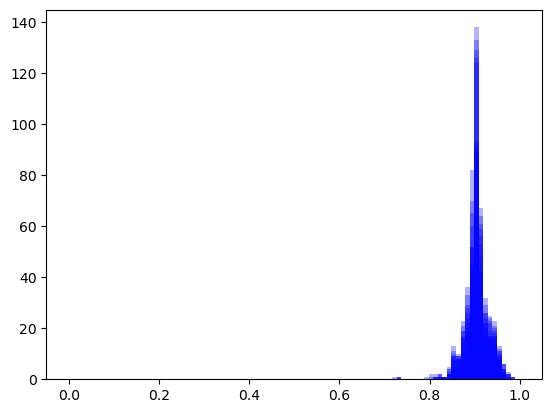

In [47]:
res_df, distr_df, _, _, _, _ = sim_split(slopp_df, 
                             stearates_df, 
                             stearates_df_not_lib,
                             pilot_phase_data_raman, 
                             N_sim, spec_type='raman',
                             alpha=alpha)

  0%|                                                     | 0/1 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_19354/3036292607.py:64: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  6.64it/s]


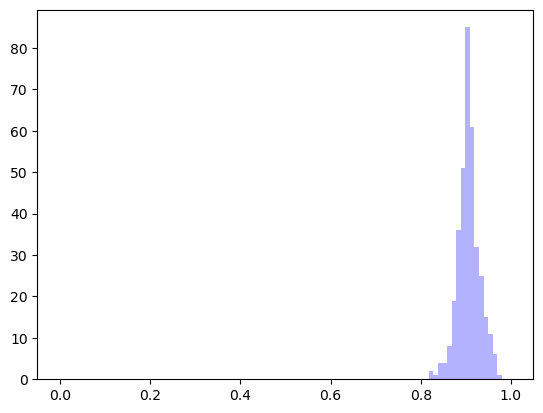

In [27]:
_, _, prediction_sets_class_df, _, _, _ = sim_split(slopp_df, 
                             stearates_df, 
                             stearates_df_not_lib,
                             pilot_phase_data_raman, 
                             N_sim=1, spec_type='raman',
                             alpha=alpha)

  0%|                                                    | 0/10 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 10%|████▍                                       | 1/10 [00:00<00:01,  5.55it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha

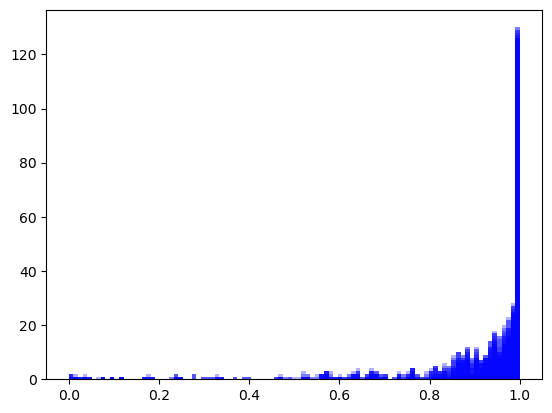

In [49]:
res_df_pcc, distr_df_pcc, _, _, _, _ = sim_split(slopp_df,
                                     stearates_df,
                                     stearates_df_not_lib,
                                     pilot_phase_data_raman, 
                                     N_sim, 
                                     spec_type='raman', 
                                     metric='pcc',
                                     alpha=alpha)


  0%|                                                     | 0/1 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_19354/3036292607.py:64: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  5.70it/s]


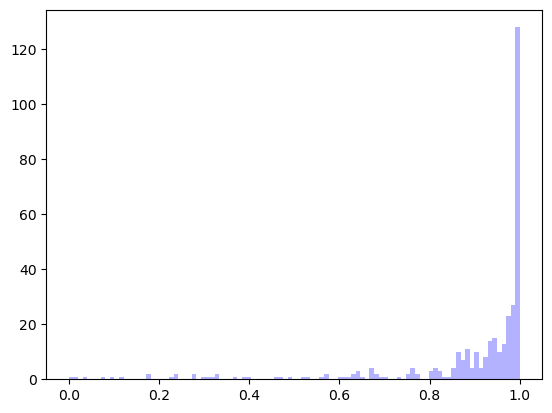

In [25]:
_, _, prediction_sets_class_df_pcc, _, _, _  = sim_split(slopp_df,
                                     stearates_df,
                                     stearates_df_not_lib,
                                     pilot_phase_data_raman, 
                                     N_sim=1, 
                                     spec_type='raman', 
                                     metric='pcc',
                                     alpha=alpha)

# Rebecca

  0%|                                                    | 0/10 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 10%|████▍                                       | 1/10 [00:00<00:01,  7.78it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha

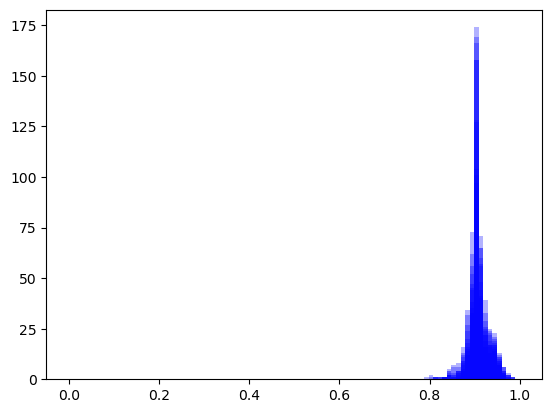

In [52]:
res_df_rb, distr_df_rb, _, _, _, _ = sim_split(rebecca_df,
                                   stearates_df,
                                   stearates_df_not_lib,
                                   pilot_phase_data_raman, 
                                   N_sim, 
                                   spec_type='raman',
                                   alpha=alpha)

In [11]:
stearates_df.groupby('polymer').count()

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3487.0,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,id
polymer,,,,,,,,,,,,,,,,,,,,,
Calcium Stearate,53,53,53,53,53,53,53,53,53,53,...,53,53,53,53,53,53,53,53,53,53
Magnesium Stearate v2,33,33,33,33,33,33,33,33,33,33,...,33,33,33,33,33,33,33,33,33,33
Sodium Stearate,38,38,38,38,38,38,38,38,38,38,...,38,38,38,38,38,38,38,38,38,38
Zinc Stearate,57,57,57,57,57,57,57,57,57,57,...,57,57,57,57,57,57,57,57,57,57


In [13]:
rebecca_df.groupby('polymer').count()

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3487.0,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,id
polymer,,,,,,,,,,,,,,,,,,,,,
PE,21,21,21,21,21,21,21,21,21,21,...,21,21,21,21,21,21,21,21,21,21


In [61]:
alpha

0.05

  0%|                                                     | 0/1 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_19354/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  7.06it/s]


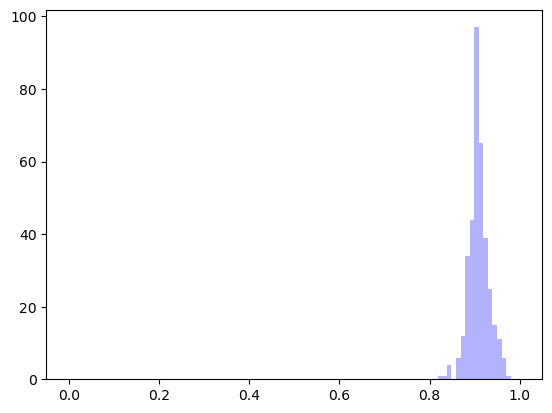

In [69]:
_, _, prediction_sets_class_df_rb, qhat_list, prediction_sets, smx_test  = sim_split(rebecca_df,
                                   stearates_df,
                                   stearates_df_not_lib,
                                   pilot_phase_data_raman, 
                                   N_sim=1, 
                                   spec_type='raman',
                                   alpha=alpha)

In [76]:
1-qhat_list[0]

0.8748692470369966

In [59]:
prediction_sets_class_df_rb

,id,class
0,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_9,polymer
1,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_12,polymer
2,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_13,both
3,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_14,polymer
4,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_16,both
...,...,...
90,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_115,both
91,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_116,both
92,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_117,polymer
93,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_118,both


  0%|                                                    | 0/10 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 10%|████▍                                       | 1/10 [00:00<00:01,  7.26it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_69338/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha

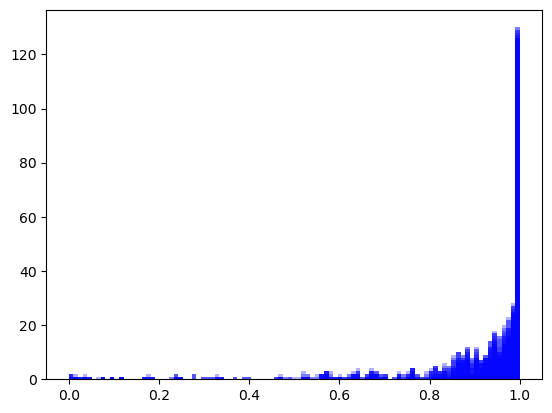

In [54]:
res_df_rb_pcc, distr_df_rb_pcc, _, _, _, _ = sim_split(rebecca_df,
                                           stearates_df,
                                           stearates_df_not_lib,
                                           pilot_phase_data_raman, 
                                           N_sim, 
                                           spec_type='raman', 
                                           metric='pcc',
                                           alpha=alpha)

  0%|                                                     | 0/1 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_19354/2116647230.py:67: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  6.75it/s]


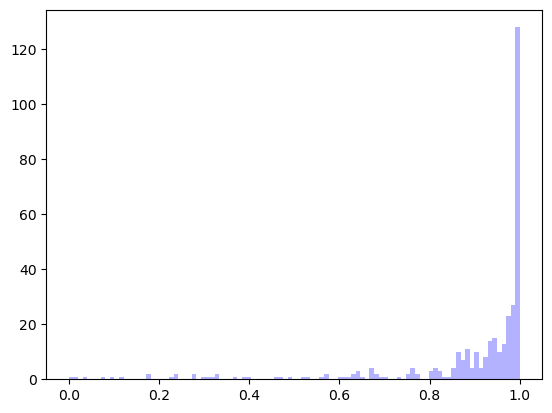

In [77]:
_, distr_df_rb_pcc, prediction_sets_class_df_rb_pcc, qhat_list, prediction_sets, smx_test = sim_split(rebecca_df,
                                           stearates_df,
                                           stearates_df_not_lib,
                                           pilot_phase_data_raman, 
                                           N_sim=1, 
                                           spec_type='raman', 
                                           metric='pcc',
                                           alpha=alpha)

In [45]:
prediction_sets_class_df_rb_pcc

,id,class
0,MEC_02_083_DC_AlSI_2_051023_06072023_Run3_1,both
1,MEC_02_083_DC_AlSI_2_051023_06072023_Run3_2,both
2,MEC_02_083_DC_AlSI_2_051023_06072023_Run3_12,both
3,MEC_02_083_DC_AlSI_2_051023_06072023_Run3_24,both
4,MEC_02_083_DC_AlSI_2_051023_06072023_Run3_45,both
5,MEC_02_083_DC_AlSI_2_051023_06072023_Run3_61,both
6,MEC_02_078_FHS_AlSI_2_051023_06072023_Run1_30,both
7,MEC_02_078_FHS_AlSI_2_051023_06072023_Run1_54,both
8,MEC_02_078_FHS_AlSI_2_051023_06072023_Run1_88,both
9,MEC_02_083_DC_AlSI_2_051023_06072023_Run2_9,both


In [71]:
smx_test

array([[0.71470745, 0.66307797, 0.73521688, 0.63912134, 0.68804872],
       [0.62234296, 0.56978967, 0.71055857, 0.55983879, 0.60225246],
       [0.6744576 , 0.68912629, 0.70200533, 0.66898035, 0.66594145],
       [0.70494197, 0.63146841, 0.76082922, 0.62532213, 0.6813279 ],
       [0.59837054, 0.57219806, 0.73761549, 0.56185352, 0.58512109],
       [0.57675886, 0.53877067, 0.70815354, 0.53118506, 0.56619735],
       [0.78282891, 0.80503428, 0.7867835 , 0.77484531, 0.76798656],
       [0.75956042, 0.78132287, 0.7438581 , 0.73800985, 0.75520675],
       [0.69682896, 0.62824252, 0.70247327, 0.60837221, 0.66721633],
       [0.73274843, 0.65402107, 0.7243539 , 0.64096638, 0.69936634],
       [0.60954244, 0.60389277, 0.77581978, 0.59726046, 0.61024512],
       [0.51657921, 0.50872666, 0.70153318, 0.50988798, 0.51876915],
       [0.96326749, 0.95433172, 0.96714464, 0.95099963, 0.9672285 ],
       [0.74960478, 0.76281037, 0.7998789 , 0.7397126 , 0.75192272],
       [0.62422326, 0.61300738, 0.

In [79]:
1-qhat_list[0]

0.24201254946759432

In [73]:
list(prediction_sets_class_df_rb_pcc['class'])

['both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both',
 'both']

In [74]:
distr_df_rb_pcc#.to_csv('results_cp_pilot/hqi_distribution.csv')

,freq,hqi
0,1.0,0.010101
1,1.0,0.020202
2,0.0,0.030303
3,1.0,0.040404
4,0.0,0.050505
...,...,...
94,10.0,0.959596
95,13.0,0.969697
96,23.0,0.979798
97,27.0,0.989899


In [10]:
qhat_list

[0.7579874505324057]

In [76]:
#prediction_sets_class_df = prediction_sets_class_df.rename({'class':'class_slopp'}, axis=1)
#prediction_sets_class_df_pcc = prediction_sets_class_df_pcc.rename({'class':'class_slopp_pcc'}, axis=1)
#prediction_sets_class_df_rb = prediction_sets_class_df_rb.rename({'class':'class_rebecca'}, axis=1)
prediction_sets_class_df_rb_pcc = prediction_sets_class_df_rb_pcc.rename({'class':'class_rebecca_pcc'}, axis=1)
prediction_sets_class_df_rb_pcc.to_csv('results_cp_pilot/classified_spectra_pred_set_raman_new_data.csv')

In [13]:
prediction_sets_class_df_all = (prediction_sets_class_df.
 merge(prediction_sets_class_df_pcc, on='id').
 merge(prediction_sets_class_df_rb, on='id').
 merge(prediction_sets_class_df_rb_pcc, on='id'))
prediction_sets_class_df_all.iloc[:,[0,3]].to_csv('results_cp_pilot/classified_spectra_pred_set_raman_full.csv')
#pd.concat([prediction_sets_class_df_all.groupby('class_slopp').count().iloc[:,:1],
#prediction_sets_class_df_all.groupby('class_slopp_pcc').count().iloc[:,:1],
#prediction_sets_class_df_all.groupby('class_rebecca').count().iloc[:,:1]
#prediction_sets_class_df_all.groupby('class_rebecca_pcc').count().iloc[:,:1],], axis=1)

NameError: name 'prediction_sets_class_df' is not defined

In [119]:
prediction_sets_class_df_all

,id,class_slopp,class_slopp_pcc,class_rebecca,class_rebecca_pcc
0,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_9,both,both,polymer,both
1,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_12,both,both,polymer,both
2,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_13,both,both,both,both
3,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_14,both,both,polymer,both
4,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_16,both,both,both,both
...,...,...,...,...,...
90,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_115,both,both,both,both
91,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_116,stearate,both,both,both
92,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_117,stearate,both,polymer,both
93,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_118,both,both,both,both


In [116]:
res_df_raman = pd.concat([res_df.iloc[:,:1],
res_df_pcc.iloc[:,:1],
res_df_rb.iloc[:,:1],
res_df_rb_pcc.iloc[:,:1]], axis=1)
res_df_raman.columns = ['nn_slopp','pcc_slopp','nn_rebecca','pcc_rebecca']
res_df_raman.iloc[:,2:3]#.to_csv('results_cp_pilot/results_raman_'+str(int((1-alpha)*100))+'.csv')

,nn_rebecca
threshold_list,0.876690
mean_prediction_set_size_list,3.560000
n_stearate_in_pred_set,2.562105
sets_zero_list,0.000000
sets_one_list,24.600000
sets_one_plus_list,70.400000
n_pred_sets_both,70.200000
n_pred_sets_polymer,24.500000
n_pred_sets_stearate,0.300000
n_pred_sets_empty,0.000000


In [115]:
res_df_raman

,nn_slopp,pcc_slopp,nn_rebecca,pcc_rebecca
threshold_list,0.860710,0.0904,0.876690,0.0904
mean_prediction_set_size_list,12.225000,21.7190,3.560000,5.0000
n_stearate_in_pred_set,3.930526,4.0000,2.562105,4.0000
sets_zero_list,0.000000,0.0000,0.000000,0.0000
sets_one_list,0.000000,0.0000,24.600000,0.0000
sets_one_plus_list,95.000000,95.0000,70.400000,95.0000
n_pred_sets_both,89.600000,95.0000,70.200000,95.0000
n_pred_sets_polymer,1.100000,0.0000,24.500000,0.0000
n_pred_sets_stearate,4.300000,0.0000,0.300000,0.0000
n_pred_sets_empty,0.000000,0.0000,0.000000,0.0000


In [15]:
pd.read_csv('results_cp/results_raman_removed_spec_unsorted_cal.csv')

,Unnamed: 0,nn_slopp,pcc_slopp,nn_rebecca,pcc_rebecca
0,threshold_list,0.877354,0.572242,0.885196,0.572242
1,mean_prediction_set_size_list,3.934040,10.962460,3.779980,6.088440
2,n_stearate_in_pred_set,3.455836,3.999187,3.022694,3.999187
3,sets_zero_list,0.000000,0.000000,0.000000,0.000000
4,sets_one_list,30.658000,0.000000,72.052000,0.000000
5,sets_one_plus_list,626.342000,657.000000,584.948000,657.000000
6,n_pred_sets_both,87.564000,601.328000,353.810000,657.000000
7,n_pred_sets_polymer,0.000000,0.000000,2.402000,0.000000
8,n_pred_sets_stearate,569.436000,55.672000,300.788000,0.000000
9,n_pred_sets_empty,0.000000,0.000000,0.000000,0.000000


In [16]:
pd.read_csv('results_cp/results_raman.csv')

,Unnamed: 0,nn_slopp,pcc_slopp,nn_rebecca,pcc_rebecca
0,threshold_list,0.8873,0.99531,0.888585,0.99531
1,mean_prediction_set_size_list,6.8515,0.03612,3.044400,0.03614
2,sets_zero_list,0.0000,1208.92200,0.000000,1208.92200
3,sets_one_list,142.8440,19.04200,362.654000,19.04200
4,sets_one_plus_list,1096.1560,11.03600,876.346000,11.03600
5,n_pred_sets_both,431.0620,0.00000,448.752000,0.01400
6,n_pred_sets_polymer,54.7740,0.00000,446.554000,0.00000
7,n_pred_sets_stearate,753.1640,30.07800,343.694000,30.06400
8,n_pred_sets_empty,0.0000,1208.92200,0.000000,1208.92200


In [17]:
#_ = plt.hist(x=np.linspace(0, 1, 100)[1:], bins=np.linspace(0, 1, 100), weights=np.concatenate(distr_list,axis=1).mean(1)/92)#


# finger print region

In [110]:
wn = np.array(slopp_df.columns[:-4])
lim_1, lim_2 = (1000,1600)
idx_fp = list(np.logical_and(wn >= lim_1, wn <= lim_2)) + [True]*4

# Slopp

  0%|                                                   | 0/100 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
  1%|▍                                          | 1/100 [00:00<00:21,  4.66it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 17%|███████▏                                  | 17/100 [00:03<00:18,  4.59it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 18%|███████▌                                  | 18/100 [00:03<00:17,  4.69it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 34%|██████████████▎                           | 34/100 [00:07<00:12,  5.21it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 35%|██████████████▋                           | 35/100 [00:07<00:12,  5.23it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 51%|█████████████████████▍                    | 51/100 [00:10<00:09,  5.03it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 52%|█████████████████████▊                    | 52/100 [00:10<00:09,  4.97it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 68%|████████████████████████████▌             | 68/100 [00:13<00:06,  5.16it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 69%|████████████████████████████▉             | 69/100 [00:14<00:06,  5.08it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 85%|███████████████████████████████████▋      | 85/100 [00:17<00:03,  4.96it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 86%|████████████████████████████████████      | 86/100 [00:17<00:02,  5.00it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

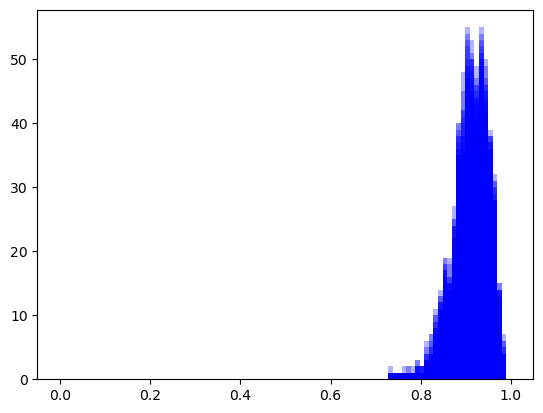

In [29]:
res_df, distr_df = sim_split(slopp_df.loc[:, idx_fp], 
                             stearates_df.loc[:, idx_fp], 
                             stearates_df_not_lib.loc[:, idx_fp],
                             pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                             N_sim, spec_type='raman',
                             alpha=alpha)

  0%|                                                   | 0/100 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
  1%|▍                                          | 1/100 [00:00<00:52,  1.88it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 17%|███████▏                                  | 17/100 [00:05<00:26,  3.08it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 18%|███████▌                                  | 18/100 [00:05<00:26,  3.09it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 34%|██████████████▎                           | 34/100 [00:11<00:20,  3.16it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 35%|██████████████▋                           | 35/100 [00:11<00:20,  3.16it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 51%|█████████████████████▍                    | 51/100 [00:16<00:15,  3.24it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 52%|█████████████████████▊                    | 52/100 [00:16<00:14,  3.22it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 68%|████████████████████████████▌             | 68/100 [00:22<00:10,  3.18it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 69%|████████████████████████████▉             | 69/100 [00:22<00:09,  3.21it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 85%|███████████████████████████████████▋      | 85/100 [00:27<00:04,  3.18it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 86%|████████████████████████████████████      | 86/100 [00:27<00:04,  3.17it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

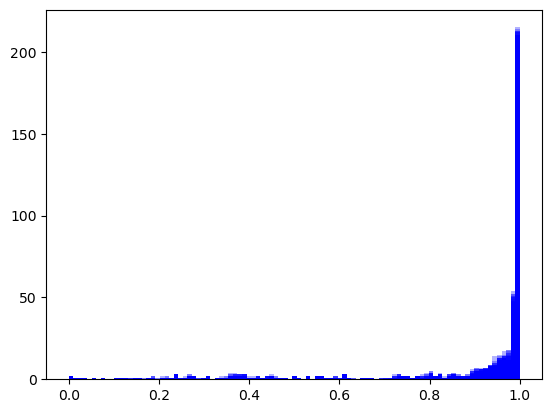

In [30]:
res_df_pcc, distr_df_pcc = sim_split(slopp_df.loc[:, idx_fp],
                                     stearates_df.loc[:, idx_fp],
                                     stearates_df_not_lib.loc[:, idx_fp],
                                     pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                                     N_sim, 
                                     spec_type='raman', 
                                     metric='pcc',
                                     alpha=alpha)


# Rebecca

  0%|                                                   | 0/100 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
  1%|▍                                          | 1/100 [00:00<00:19,  5.14it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 17%|███████▏                                  | 17/100 [00:03<00:15,  5.42it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 18%|███████▌                                  | 18/100 [00:03<00:14,  5.51it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 34%|██████████████▎                           | 34/100 [00:06<00:10,  6.12it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 35%|██████████████▋                           | 35/100 [00:06<00:10,  6.19it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 51%|█████████████████████▍                    | 51/100 [00:08<00:07,  6.16it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 52%|█████████████████████▊                    | 52/100 [00:09<00:07,  6.15it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 68%|████████████████████████████▌             | 68/100 [00:11<00:05,  6.27it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 69%|████████████████████████████▉             | 69/100 [00:11<00:04,  6.23it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 85%|███████████████████████████████████▋      | 85/100 [00:14<00:02,  6.09it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 86%|████████████████████████████████████      | 86/100 [00:14<00:02,  6.02it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

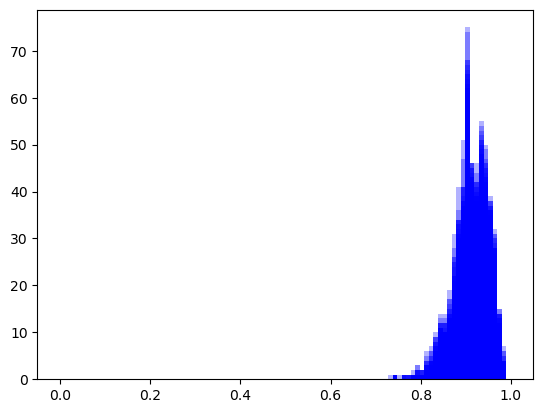

In [31]:
res_df_rb, distr_df_rb = sim_split(rebecca_df.loc[:, idx_fp],
                                   stearates_df.loc[:, idx_fp],
                                   stearates_df_not_lib.loc[:, idx_fp],
                                   pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                                   N_sim, 
                                   spec_type='raman',
                                   alpha=alpha)

  0%|                                                   | 0/100 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
  1%|▍                                          | 1/100 [00:00<00:19,  5.17it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 17%|███████▏                                  | 17/100 [00:03<00:16,  5.12it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 18%|███████▌                                  | 18/100 [00:03<00:15,  5.19it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 34%|██████████████▎                           | 34/100 [00:06<00:12,  5.23it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 35%|██████████████▋                           | 35/100 [00:06<00:12,  5.24it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 51%|█████████████████████▍                    | 51/100 [00:09<00:09,  5.20it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 52%|█████████████████████▊                    | 52/100 [00:10<00:09,  5.23it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 68%|████████████████████████████▌             | 68/100 [00:13<00:06,  5.24it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 69%|████████████████████████████▉             | 69/100 [00:13<00:05,  5.23it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

 85%|███████████████████████████████████▋      | 85/100 [00:16<00:03,  4.90it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
 86%|████████████████████████████████████      | 86/100 [00:16<00:02,  5.01it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/336450567.py:65: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, 

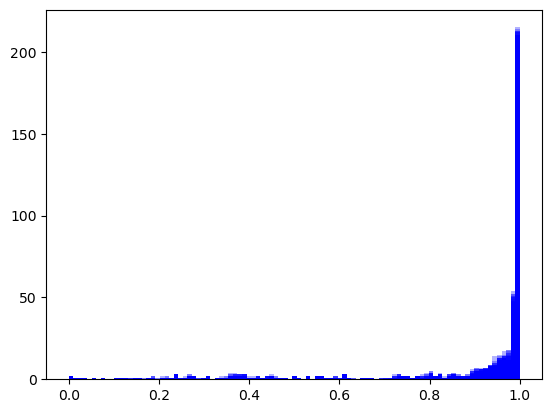

In [32]:
res_df_rb_pcc, distr_df_rb_pcc = sim_split(rebecca_df.loc[:, idx_fp],
                                           stearates_df.loc[:, idx_fp],
                                           stearates_df_not_lib.loc[:, idx_fp],
                                           pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                                           N_sim, 
                                           spec_type='raman', 
                                           metric='pcc',
                                           alpha=alpha)

  0%|                                                     | 0/1 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_97704/3188894632.py:66: DeprecationWarning: the `interpolation=` argument to nanquantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal, n, alpha, cond=0)
  0%|                                                     | 0/1 [00:00<?, ?it/s]/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_

,id,class_slopp,class_slopp_pcc,class_rebecca,class_rebecca_pcc
0,KC_L_02_0425_1,both,both,both,both
1,KC_L_02_0425_2,both,both,both,both
2,KC_L_02_0425_6,both,both,both,both
3,KC_L_02_0425_7,both,both,both,both
4,KC_L_02_0425_8,both,both,both,both
...,...,...,...,...,...
651,KC_N_02_0328_28,both,both,both,both
652,KC_N_02_0328_29,both,both,both,both
653,KC_N_02_0328_30,both,both,both,both
654,KC_N_02_0328_31,stearate,both,stearate,both


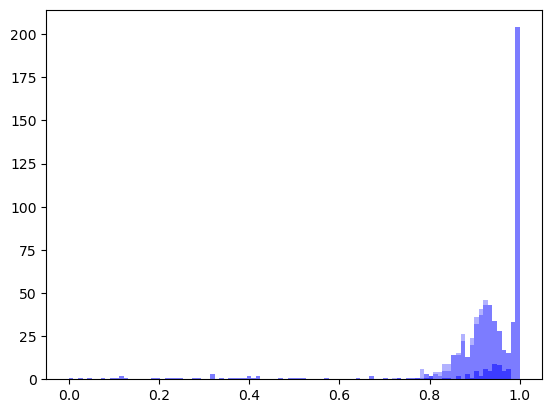

In [111]:
_, _, prediction_sets_class_df = sim_split(slopp_df.loc[:, idx_fp], 
                             stearates_df.loc[:, idx_fp], 
                             stearates_df_not_lib.loc[:, idx_fp],
                             pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                             N_sim=1, spec_type='raman',
                             alpha=alpha)

_, _, prediction_sets_class_df_pcc = sim_split(slopp_df.loc[:, idx_fp],
                                     stearates_df.loc[:, idx_fp],
                                     stearates_df_not_lib.loc[:, idx_fp],
                                     pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                                     N_sim=1, 
                                     spec_type='raman', 
                                     metric='pcc',
                                     alpha=alpha)

_, _, prediction_sets_class_df_rb  = sim_split(rebecca_df.loc[:, idx_fp],
                                   stearates_df.loc[:, idx_fp],
                                   stearates_df_not_lib.loc[:, idx_fp],
                                   pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                                   N_sim=1, 
                                   spec_type='raman',
                                   alpha=alpha)

_, _, prediction_sets_class_df_rb_pcc = sim_split(rebecca_df.loc[:, idx_fp],
                                           stearates_df.loc[:, idx_fp],
                                           stearates_df_not_lib.loc[:, idx_fp],
                                           pilot_phase_data_raman.loc[:, idx_fp+[True]], 
                                           N_sim=1, 
                                           spec_type='raman', 
                                           metric='pcc',
                                           alpha=alpha)

prediction_sets_class_df = prediction_sets_class_df.rename({'class':'class_slopp'}, axis=1)
prediction_sets_class_df_pcc = prediction_sets_class_df_pcc.rename({'class':'class_slopp_pcc'}, axis=1)
prediction_sets_class_df_rb = prediction_sets_class_df_rb.rename({'class':'class_rebecca'}, axis=1)
prediction_sets_class_df_rb_pcc = prediction_sets_class_df_rb_pcc.rename({'class':'class_rebecca_pcc'}, axis=1)

prediction_sets_class_df_all = (prediction_sets_class_df.
 merge(prediction_sets_class_df_pcc, on='id').
 merge(prediction_sets_class_df_rb, on='id').
 merge(prediction_sets_class_df_rb_pcc, on='id'))
prediction_sets_class_df_all.to_csv('results_cp/classified_spectra_pred_set_raman_finger_print_'+str(lim_1)+'_'+str(lim_2)+'_'+str(int((1-alpha)*100))+'.csv')
prediction_sets_class_df_all

In [112]:
'results_cp/classified_spectra_pred_set_raman_finger_print_'+str(lim_1)+'_'+str(lim_2)+'_'+str(int((1-alpha)*100))+'.csv'


'results_cp/classified_spectra_pred_set_raman_finger_print_1000_1600_95.csv'

In [114]:
#pilot_phase_data_raman.to_csv('results_cp/pilot_phase_data_raman.csv')

In [113]:
pd.concat([prediction_sets_class_df_all.groupby('class_slopp').count().iloc[:,:1],
prediction_sets_class_df_all.groupby('class_slopp_pcc').count().iloc[:,:1],
prediction_sets_class_df_all.groupby('class_rebecca').count().iloc[:,:1],
prediction_sets_class_df_all.groupby('class_rebecca_pcc').count().iloc[:,:1],], axis=1)

,id,id,id,id
both,447,656.0,622,656.0
stearate,209,NaN,34,NaN


In [36]:
res_df_raman = pd.concat([res_df.iloc[:,:1],
res_df_pcc.iloc[:,:1],
res_df_rb.iloc[:,:1],
res_df_rb_pcc.iloc[:,:1]], axis=1)
res_df_raman.columns = ['nn_slopp','pcc_slopp','nn_rebecca','pcc_rebecca']
res_df_raman.to_csv('results_cp/results_raman_removed_spec_unsorted_cal_finger_print_'+str(lim_1)+'_'+str(lim_2)+'_'+str(int((1-alpha)*100))+'.csv')
res_df_raman


,nn_slopp,pcc_slopp,nn_rebecca,pcc_rebecca
threshold_list,0.846551,-0.058899,0.852875,-0.058899
mean_prediction_set_size_list,6.498100,22.549800,4.828800,7.000000
n_stearate_in_pred_set,3.839985,4.000000,3.681570,4.000000
sets_zero_list,0.000000,0.000000,0.000000,0.000000
sets_one_list,12.460000,0.000000,15.010000,0.000000
sets_one_plus_list,643.540000,656.000000,640.990000,656.000000
n_pred_sets_both,365.940000,656.000000,581.760000,656.000000
n_pred_sets_polymer,0.030000,0.000000,2.920000,0.000000
n_pred_sets_stearate,290.030000,0.000000,71.320000,0.000000
n_pred_sets_empty,0.000000,0.000000,0.000000,0.000000


In [26]:
res_df_raman = pd.concat([res_df.iloc[:,:1],
res_df_pcc.iloc[:,:1],
res_df_rb.iloc[:,:1],
res_df_rb_pcc.iloc[:,:1]], axis=1)
res_df_raman.columns = ['nn_slopp','pcc_slopp','nn_rebecca','pcc_rebecca']
res_df_raman#.to_csv('results_cp/results_raman_removed_spec_unsorted_cal_finger_print_'+str(lim_1)+'_'+str(lim_2)+'_'+str(int((1-alpha)*100))+'.csv')
#res_df_raman

,nn_slopp,pcc_slopp,nn_rebecca,pcc_rebecca
threshold_list,0.825192,0.131660,0.822535,0.131660
mean_prediction_set_size_list,9.121200,17.037400,5.664100,6.865400
n_stearate_in_pred_set,3.947713,3.999832,3.950137,3.999832
sets_zero_list,0.000000,0.000000,0.000000,0.000000
sets_one_list,3.330000,0.000000,2.670000,0.000000
sets_one_plus_list,652.670000,656.000000,653.330000,656.000000
n_pred_sets_both,532.290000,656.000000,628.440000,656.000000
n_pred_sets_polymer,0.000000,0.000000,0.030000,0.000000
n_pred_sets_stearate,123.710000,0.000000,27.530000,0.000000
n_pred_sets_empty,0.000000,0.000000,0.000000,0.000000


# PTIR

In [20]:
flopp_df_trans = pd.read_csv('flopp_data_ir_final_transmission.csv')
del flopp_df_trans['Unnamed: 0']

flopp_df = pd.read_csv('flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])

rebecca_df = pd.read_csv('rebecca_data_ir_final.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)

stearates_df = pd.read_csv('stearates_data_ir_final.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])
#stearates_df['polymer'] = "Stearate"

stearates_df_not_lib = pd.read_csv('stearates_data_not_lib_ir_final.csv')
del stearates_df_not_lib['Unnamed: 0']
stearates_df_not_lib.columns = list(np.float64(stearates_df_not_lib.columns[:-4])) + list(stearates_df_not_lib.columns[-4:])

gloves_data_ir = pd.read_csv('gloves_data_ir_final.csv')
del gloves_data_ir['Unnamed: 0']
gloves_data_ir.columns = list(np.float64(gloves_data_ir.columns[:-4])) + list(gloves_data_ir.columns[-4:])
gloves_data_ir = gloves_data_ir.query('background == "no_background"').reset_index(drop=True)
gloves_data_ir['polymer'] = ''
gloves_data_ir['label'] = ''

matches_all_ir = pd.read_csv('results/matches_all_ir.csv')
idx_str_matches_ir = matches_all_ir.query('hqi_stearates >=.7').loc[:,['id']]#,

gloves_data_ir = gloves_data_ir.merge(idx_str_matches_ir, on='id').reset_index(drop=True)
gloves_data_ir

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2963.0,2965.0,2967.0,2969.0,map_x,map_y,id,background,polymer,label
0,-0.983209,-0.977079,-0.931675,-0.885621,-0.865748,-0.839986,-0.824942,-0.825400,-0.823768,-0.814618,...,1.868649,1.815011,1.720470,1.662378,15576.000000,1627.599976,MF_L_01_0514_17,no_background,,
1,-0.709079,-0.707761,-0.708681,-0.707403,-0.704321,-0.703580,-0.703898,-0.702983,-0.702249,-0.700777,...,4.984752,4.922716,4.894918,4.944714,17550.500000,3435.649902,MF_L_01_0514_23,no_background,,
2,-1.235459,-1.224247,-1.223558,-1.216231,-1.208195,-1.206158,-1.202009,-1.189896,-1.175776,-1.168123,...,3.043476,3.109038,3.186144,3.222656,17456.099609,3222.350098,MF_L_01_0514_32,no_background,,
3,-0.688929,-0.679863,-0.701395,-0.713241,-0.701296,-0.673999,-0.659115,-0.661535,-0.658879,-0.650866,...,3.525264,3.581098,3.694472,3.789030,17522.500000,3924.000000,MF_L_01_0514_56,no_background,,
4,-0.737863,-0.726139,-0.718975,-0.721719,-0.721018,-0.717991,-0.717197,-0.707673,-0.695849,-0.691718,...,2.197397,2.194271,2.182159,2.173829,17508.400391,3771.850098,MF_L_01_0514_72,no_background,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,-0.463448,-0.461379,-0.462904,-0.463821,-0.461637,-0.459418,-0.459653,-0.459580,-0.460255,-0.460049,...,0.640725,0.562024,0.446629,0.318549,-4531.649902,-1766.150024,KC_N_02_0328_25,no_background,,
672,-0.480291,-0.480738,-0.481060,-0.482651,-0.483256,-0.482391,-0.481551,-0.481103,-0.481177,-0.481517,...,0.944865,0.833614,0.692843,0.546092,-4553.850098,-1765.500000,KC_N_02_0328_26,no_background,,
673,-0.274678,-0.281003,-0.293222,-0.296954,-0.289273,-0.292848,-0.307613,-0.306951,-0.304668,-0.308887,...,0.286158,0.142908,0.056841,0.013463,-4543.500000,-1759.750000,KC_N_02_0328_28,no_background,,
674,-0.293702,-0.290652,-0.277945,-0.267897,-0.278808,-0.290650,-0.291072,-0.288077,-0.285583,-0.284491,...,0.000310,-0.012789,-0.059711,-0.145868,-4501.899902,-1758.099976,KC_N_02_0328_29,no_background,,


100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:20<00:00,  4.83it/s]


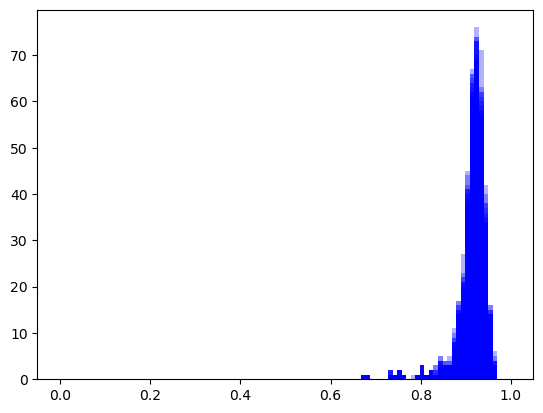

In [21]:
res_df_fl, distr_df_fl = sim_split(flopp_df,
                                   stearates_df, 
                                   stearates_df_not_lib,
                                   gloves_data_ir, 
                                   N_sim, 
                                   spec_type='ir',
                                   alpha=alpha)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:27<00:00,  3.70it/s]


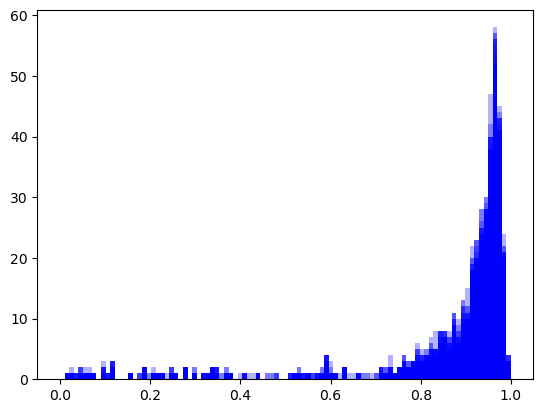

In [22]:
res_df_fl_pcc, distr_df_fl_pcc = sim_split(flopp_df,
                                           stearates_df,
                                           stearates_df_not_lib,
                                           gloves_data_ir, 
                                           N_sim, 
                                           spec_type='ir', 
                                           metric='pcc',
                                           alpha=alpha)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:16<00:00,  6.16it/s]


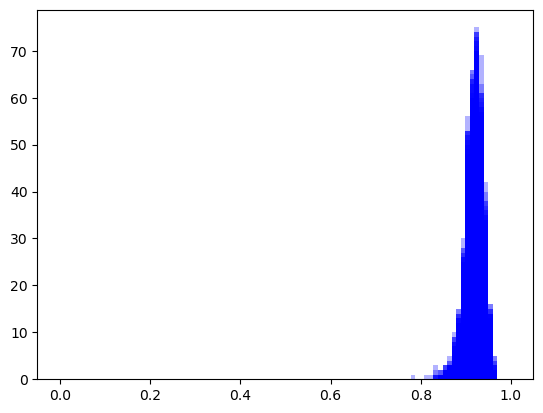

In [23]:
res_df_rb_r, distr_df_rb_r = sim_split(rebecca_df,
                                       stearates_df,
                                       stearates_df_not_lib,
                                       gloves_data_ir, 
                                       N_sim, 
                                       spec_type='ir',
                                       alpha=alpha)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:21<00:00,  4.61it/s]


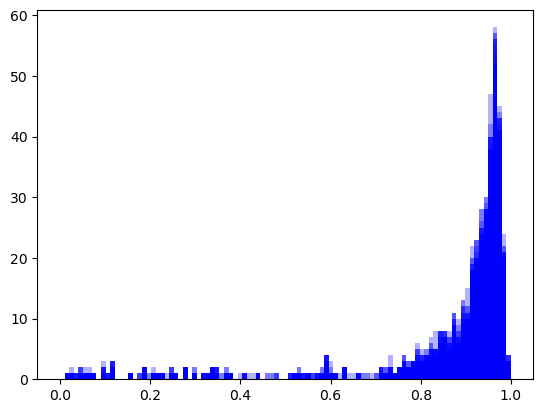

In [24]:
res_df_rb_r_pcc, distr_df_rb_r_pcc = sim_split(rebecca_df,
                                               stearates_df,
                                               stearates_df_not_lib,
                                               gloves_data_ir, 
                                               N_sim, 
                                               spec_type='ir', 
                                               metric='pcc',
                                               alpha=alpha)

In [26]:
res_df_ir = pd.concat([res_df_fl.iloc[:,:1],
           res_df_fl_pcc.iloc[:,:1],
           res_df_rb_r.iloc[:,:1],
           res_df_rb_r_pcc.iloc[:,:1]], axis=1)#.set_index('')
res_df_ir.columns = ['nn_flopp','pcc_flopp','nn_rebecca','pcc_rebecca']
res_df_ir.to_csv('results_cp/results_ir_removed_spec_unsorted_cal'+str(int((1-alpha)*100))+'.csv')

In [24]:
pd.read_csv('results_cp/results_ir_removed_spec_unsorted_cal.csv')

,Unnamed: 0,nn_flopp,pcc_flopp,nn_rebecca,pcc_rebecca
0,threshold_list,0.886252,0.346469,0.895957,0.346469
1,mean_prediction_set_size_list,2.303040,10.818800,1.544260,6.936480
2,n_stearate_in_pred_set,1.654000,4.000000,0.928279,4.000000
3,sets_zero_list,0.000000,0.000000,0.000000,0.000000
4,sets_one_list,319.494000,0.000000,397.908000,0.000000
5,sets_one_plus_list,362.506000,682.000000,284.092000,682.000000
6,n_pred_sets_both,217.276000,682.000000,226.958000,678.052000
7,n_pred_sets_polymer,1.750000,0.000000,175.210000,0.000000
8,n_pred_sets_stearate,462.974000,0.000000,279.832000,3.948000
9,n_pred_sets_empty,0.000000,0.000000,0.000000,0.000000


In [25]:
pd.read_csv('results_cp/results_ir_removed_spec.csv')

,Unnamed: 0,nn_flopp,pcc_flopp,nn_rebecca,pcc_rebecca
0,threshold_list,0.901975,0.906154,0.901096,0.906154
1,mean_prediction_set_size_list,1.175420,2.525300,1.229120,2.778840
2,n_stearate_in_pred_set,1.034202,1.712117,0.716370,1.712117
3,sets_zero_list,6.562000,177.920000,4.246000,162.800000
4,sets_one_list,589.790000,49.962000,540.034000,27.440000
5,sets_one_plus_list,85.648000,454.118000,137.720000,491.760000
6,n_pred_sets_both,47.570000,298.958000,110.608000,461.116000
7,n_pred_sets_polymer,25.822000,2.344000,233.654000,17.464000
8,n_pred_sets_stearate,602.046000,202.778000,333.492000,40.620000
9,n_pred_sets_empty,6.562000,177.920000,4.246000,162.800000


In [26]:
pd.read_csv('results_cp/results_ir.csv')

,Unnamed: 0,nn_flopp,pcc_flopp,nn_rebecca,pcc_rebecca
0,threshold_list,0.901975,0.906154,0.901096,0.906154
1,mean_prediction_set_size_list,1.830620,1.433600,1.791120,1.561400
2,sets_zero_list,32.500000,696.310000,15.222000,694.658000
3,sets_one_list,840.810000,60.862000,767.144000,27.216000
4,sets_one_plus_list,340.690000,456.828000,431.634000,492.126000
5,n_pred_sets_both,211.896000,298.958000,329.770000,461.482000
6,n_pred_sets_polymer,276.608000,15.954000,396.230000,17.606000
7,n_pred_sets_stearate,692.996000,202.778000,472.778000,40.254000
8,n_pred_sets_empty,32.500000,696.310000,15.222000,694.658000


In [27]:
#prediction_sets_df = pd.DataFrame(prediction_sets) * 1
#prediction_sets_df.columns = label_table['polymer']
#pd.DataFrame({p:[np.sum([p in x for x in output_df['prection_set']])] for p in label_table['polymer']}).T

In [28]:
## Manual check
#i = mult_label[0]
#for i in mult_label:
#    print('Prediction Set: ', prediction_sets_n[i])
#    plt.plot(wl_list, X_test[i])
#    plt.show()